# Optimisation de portefeuille — Équation de Hamilton–Jacobi–Bellman (modèle de Merton)

Résolution numérique de l'équation HJB du problème de Merton par différences finies (schémas explicite, implicite avec itération de Howard, et semi-implicite de type Crank–Nicolson), validation contre la solution analytique et étude de convergence.

*Projet académique — INSA Rouen Normandie (2025–2026)*

 ## 1.Imports et installation

In [2]:
import numpy as np
import matplotlib.pyplot as plt



## 2.Définition des paramètres financiers

In [3]:
# --- Paramètres financiers ---
r = 0.02            # taux sans risque
mu = 0.08           # drift de l'actif
sigma = 0.2         # volatilité
gamma = 2.0         # aversion au risque
T = 1.0             # horizon temporel (1 an)

# --- Domaine numérique en richesse ---
x_min, x_max = 1e-3, 5.0
Nx, Nt = 400, 200
dx = (x_max - x_min) / Nx
dt = T / Nt

# --- Grilles spatiale et temporelle ---
x = np.linspace(x_min, x_max, Nx + 1)
t = np.linspace(0, T, Nt + 1)

# --- Utilité CRRA et solution exacte (cas de Merton) ---
def U(x):
    """Utilité CRRA."""
    return (x**(1 - gamma)) / (1 - gamma)

def V_exact(t, x, r, mu, sigma, gamma, T):
    """Solution analytique du problème de Merton."""
    A = (1 - gamma) * (r + (mu - r)**2 / (2 * gamma * sigma**2))
    return U(x) * np.exp(A * (T - t))

# Stratégie optimale dans le modèle de Merton (constante)
pi_merton = (mu - r) / (gamma * sigma**2)
print("π* de Merton =", pi_merton)


π* de Merton = 0.7499999999999998


## 3. Schéma Explicite 

### 3.1.Fonction : Solveur HJB Explicite

In [4]:
def solve_HJB_explicit(r, mu, sigma, gamma, T, U, x_min=1e-3, x_max=5.0, Nx=400, Nt=200):
    """
    Schéma explicite pour l'équation de Hamilton–Jacobi–Bellman
    Retourne V(t,x) et la grille x.
    """

    # Grilles et pas
    dx = (x_max - x_min) / Nx
    dt = T / Nt
    x = np.linspace(x_min, x_max, Nx + 1)


    V = np.zeros((Nt + 1, Nx + 1))
    V[-1, :] = U(x)

    # Résolution backward en temps
    for n in reversed(range(Nt)):

        # Dérivées première et seconde (centrées)
        Vx = np.zeros_like(x)
        Vxx = np.zeros_like(x)

        Vx[1:-1] = (V[n+1, 2:] - V[n+1, :-2]) / (2 * dx)
        Vxx[1:-1] = (V[n+1, 2:] - 2 * V[n+1, 1:-1] + V[n+1, :-2]) / (dx**2)

        # Conditions de Neumann (simple copie des valeurs internes)
        Vx[0], Vx[-1] = Vx[1], Vx[-2]
        Vxx[0], Vxx[-1] = Vxx[1], Vxx[-2]

        # Stratégie optimale explicite 
        pi = - (mu - r) * Vx / (sigma**2 * x * Vxx)
        pi = np.clip(pi, -2, 2)   # bornes pour stabilité numérique

        # Terme de la HJB
        drift = x * (r + pi * (mu - r)) * Vx
        diff  = 0.5 * x**2 * (pi**2) * sigma**2 * Vxx

        # Mise à jour explicite
        V[n, :] = V[n+1, :] - dt * (drift + diff)

    return V, x


### 3.2.Exécution : Schéma Explicite

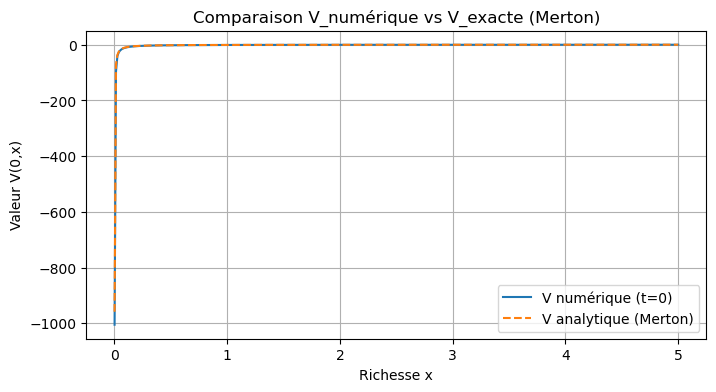

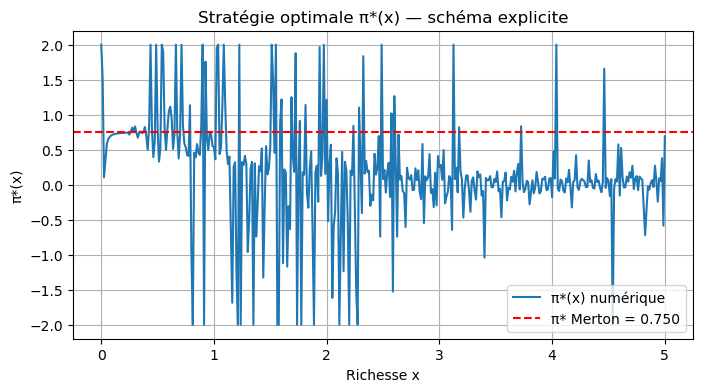

=== ORDRE DE CONVERGENCE (L∞ intérieur uniquement) ===
Ordre L∞ intérieur : 0.039


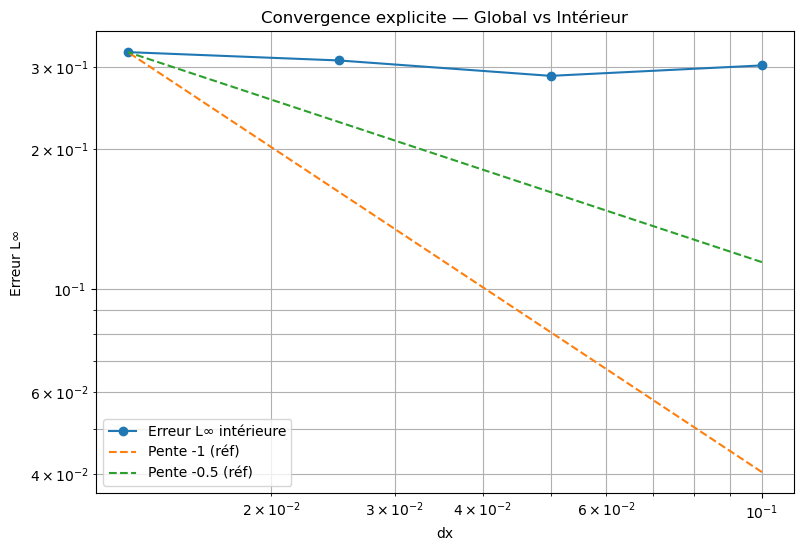


=== ERREURS ===
dx=9.9980e-02 | L∞ global=4.2299e+01 | L∞ intérieur=3.0196e-01
dx=4.9990e-02 | L∞ global=4.2966e+01 | L∞ intérieur=2.8675e-01
dx=2.4995e-02 | L∞ global=4.4239e+01 | L∞ intérieur=3.0945e-01
dx=1.2497e-02 | L∞ global=4.6556e+01 | L∞ intérieur=3.2250e-01


In [5]:
# ==============================================================
# 1) Résolution explicite et comparaison avec la solution exacte
# ==============================================================

V_exp, xgrid = solve_HJB_explicit(r, mu, sigma, gamma, T, U)

# Solution analytique (Merton)
V_theo = V_exact(0, xgrid, r, mu, sigma, gamma, T)

plt.figure(figsize=(8, 4))
plt.plot(xgrid, V_exp[0, :], label="V numérique (t=0)")
plt.plot(xgrid, V_theo, '--', label="V analytique (Merton)")
plt.xlabel("Richesse x")
plt.ylabel("Valeur V(0,x)")
plt.title("Comparaison V_numérique vs V_exacte (Merton)")
plt.grid(True)
plt.legend()
plt.show()

# ==============================================================
# 2) Stratégie optimale π*(x) à t=0
# ==============================================================

Vx0  = np.gradient(V_exp[0, :], xgrid)
Vxx0 = np.gradient(Vx0, xgrid)

pi0 = - (mu - r) * Vx0 / (sigma**2 * xgrid * Vxx0)
pi0 = np.clip(pi0, -2, 2)

plt.figure(figsize=(8, 4))
plt.plot(xgrid, pi0, label="π*(x) numérique")
plt.axhline(pi_merton, color='r', linestyle='--', label=f"π* Merton = {pi_merton:.3f}")
plt.xlabel("Richesse x")
plt.ylabel("π*(x)")
plt.title("Stratégie optimale π*(x) — schéma explicite")
plt.grid(True)
plt.legend()
plt.show()

# ==============================================================
# Test de convergence : L∞ global + L∞ intérieur
# ==============================================================

resolutions = [50, 100, 200, 400]
errors_Linf_global = []
errors_Linf_inner  = []
dx_values = []

eps = 0.05   # retirer 5% du domaine aux bords

for Nx_test in resolutions:

    dx = (x_max - x_min) / Nx_test
    dx_values.append(dx)

    # --- Résolution numérique ---
    V_tmp, x_tmp = solve_HJB_explicit(
        r, mu, sigma, gamma, T, U,
        x_min=x_min, x_max=x_max, Nx=Nx_test, Nt=Nt
    )

    # --- Solution exacte ---
    V_th = V_exact(0, x_tmp, r, mu, sigma, gamma, T)

    # --- Erreur globale L∞ ---
    err_global = np.max(np.abs(V_tmp[0, :] - V_th))
    errors_Linf_global.append(err_global)

    # --- Erreur intérieure L∞ ---
    mask = (x_tmp > x_min + eps*(x_max-x_min)) & \
           (x_tmp < x_max - eps*(x_max-x_min))

    err_inner = np.max(np.abs(V_tmp[0, mask] - V_th[mask]))
    errors_Linf_inner.append(err_inner)


# ==============================================================
# Ordre de convergence : seulement L∞ intérieur
# ==============================================================

dx_values = np.array(dx_values)
log_dx     = np.log(dx_values)
log_err_in = np.log(errors_Linf_inner)

order_inner = -np.polyfit(log_dx, log_err_in, 1)[0]

print("=== ORDRE DE CONVERGENCE (L∞ intérieur uniquement) ===")
print(f"Ordre L∞ intérieur : {order_inner:.3f}")


# ==============================================================
# Graphique comparatif erreurs
# ==============================================================

plt.figure(figsize=(9,6))
plt.loglog(dx_values, errors_Linf_inner,  'o-', label="Erreur L∞ intérieure")

# Références pente -1 et -0.5 basées sur la dernière erreur intérieure
ref = errors_Linf_inner[-1]
plt.loglog(dx_values, ref*(dx_values/dx_values[-1])**(-1),
           '--', label="Pente -1 (réf)")
plt.loglog(dx_values, ref*(dx_values/dx_values[-1])**(-0.5),
           '--', label="Pente -0.5 (réf)")

plt.xlabel("dx")
plt.ylabel("Erreur L∞")
plt.title("Convergence explicite — Global vs Intérieur")
plt.grid(True, which="both")
plt.legend()
plt.show()


# ==============================================================
# Tableau des erreurs
# ==============================================================

print("\n=== ERREURS ===")
for dx, e1, e2 in zip(dx_values, errors_Linf_global, errors_Linf_inner):
    print(f"dx={dx:.4e} | L∞ global={e1:.4e} | L∞ intérieur={e2:.4e}")


## 4. Schéma Implicite — Euler arrière

### 4.1.Fonction : Solveur HJB Implicite

In [6]:
import numpy as np

# ==========================================================================
# 1) Dérivée numérique monotone pour U'(x)
# ==========================================================================
def U_prime_num(U, x, dx):
    if x > dx:
        return (U(x) - U(x-dx)) / dx   # backward
    else:
        return (U(x+dx) - U(x)) / dx   # forward


# ==========================================================================
# 2) Solveur tridiagonal 
# ==========================================================================
def solve_tridiag(lower, diag, upper, rhs):
    n = len(diag)
    a, b, c, d = lower.copy().astype(float), diag.copy().astype(float), upper.copy().astype(float), rhs.copy().astype(float)

    for i in range(1, n):
        m = a[i] / b[i-1]
        b[i] -= m * c[i-1]
        d[i] -= m * d[i-1]

    x = np.zeros(n)
    x[-1] = d[-1] / b[-1]
    for i in range(n-2, -1, -1):
        x[i] = (d[i] - c[i]*x[i+1]) / b[i]
    return x


# ==========================================================================
# 3) Construction de (I + dt L_pi) 
# ==========================================================================
def build_system_coeffs(pi_vec, r, mu, sigma, x, dx, dt):
    N = len(x)-1
    a = x * (r + pi_vec*(mu-r))
    b = 0.5 * x**2 * pi_vec**2 * sigma**2
    b = np.maximum(b, 1e-12)

    lower = np.zeros(N+1)
    upper = np.zeros(N+1)
    diag  = np.ones(N+1)

    for i in range(1, N):
        diff = dt * b[i] / dx**2
        if a[i] >= 0:
            conv_l = dt*a[i]/dx
            conv_r = 0
        else:
            conv_l = 0
            conv_r = -dt*a[i]/dx

        lower[i] = -(diff + conv_l)
        upper[i] = -(diff + conv_r)
        diag[i]  = 1 + 2*diff + conv_l + conv_r

    diag[0]  = 1;  upper[0] = -1
    diag[-1] = 1;  lower[-1] = -1
    return lower, diag, upper


# ==========================================================================
# 4) Howard — amélioration de politique 
# ==========================================================================
def improve_policy(V, x, dx, r, mu, sigma, pi_grid, pi_ref):
    N = len(x)-1
    Vx  = np.zeros_like(V)
    Vxx = np.zeros_like(V)

    # drift basé sur la politique précédente
    a_pi = x * (r + pi_ref*(mu-r))

    for i in range(1, N):
        if a_pi[i] >= 0:
            Vx[i] = (V[i] - V[i-1]) / dx       # backward
        else:
            Vx[i] = (V[i+1] - V[i]) / dx       # forward

        Vxx[i] = (V[i+1] - 2*V[i] + V[i-1]) / dx**2

    Vx[0], Vx[-1] = Vx[1], Vx[-2]
    Vxx[0], Vxx[-1] = Vxx[1], Vxx[-2]

    best_val = np.full_like(V, -1e300)
    best_pi  = np.zeros_like(V)

    for pi in pi_grid:
        a_pi2 = x * (r + pi*(mu-r))
        b_pi2 = 0.5 * x**2 * pi**2 * sigma**2
        score = a_pi2 * Vx + b_pi2 * Vxx

        m = score > best_val
        best_val[m] = score[m]
        best_pi[m] = pi

    best_pi[0], best_pi[-1] = best_pi[1], best_pi[-2]
    return best_pi


# ==========================================================================
# 5) SCHÉMA IMPLICITE FINAL 
# ==========================================================================
def solve_HJB_implicite(r, mu, sigma, gamma, T, U,
                       x_min=1e-3, x_max=5.0, Nx=400, Nt=200,
                       pi_min=-5, pi_max=5, n_pi=101,
                       tol_pi=1e-4, max_hw=5):

    dx = (x_max - x_min)/Nx
    dt = T/Nt
    x  = np.linspace(x_min, x_max, Nx+1)
    t_grid = np.linspace(0, T, Nt+1)

    pi_grid = np.linspace(pi_min, pi_max, n_pi)

    V = np.zeros((Nt+1, Nx+1))
    V[-1,:] = U(x)

    pi_all = np.zeros_like(V)

    pi_mert = (mu-r)/(gamma*sigma**2)
    pi_guess = np.full(Nx+1, np.clip(pi_mert, pi_min, pi_max))

    for n in range(Nt-1, -1, -1):

        rhs = V[n+1,:].copy()
        rhs[0]  = V[n+1,1]  - dx * U_prime_num(U, x[0], dx)
        rhs[-1] = V[n+1,-2] + dx * U_prime_num(U, x[-1], dx)

        pi_k = pi_guess.copy()

        for k in range(max_hw):
            lower, diag, upper = build_system_coeffs(pi_k, r, mu, sigma, x, dx, dt)
            Vn = solve_tridiag(lower, diag, upper, rhs)
            pi_new = improve_policy(Vn, x, dx, r, mu, sigma, pi_grid, pi_k)

            if np.max(np.abs(pi_new - pi_k)) < tol_pi:
                break
            pi_k = pi_new

        V[n,:] = Vn
        pi_all[n,:] = pi_k
        pi_guess = pi_k.copy()

    return V, pi_all, x, t_grid


### 4.2.Exécution : Schéma Implicite

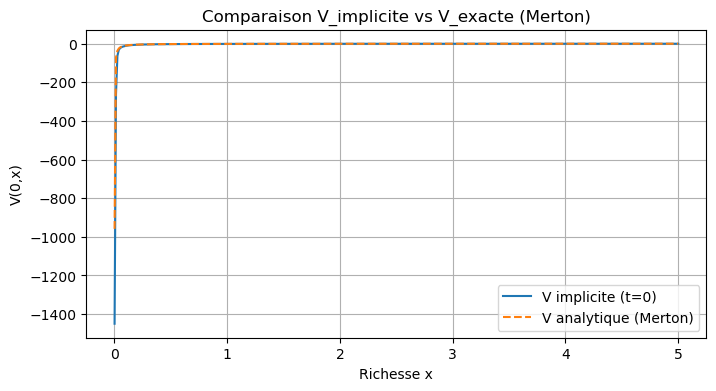

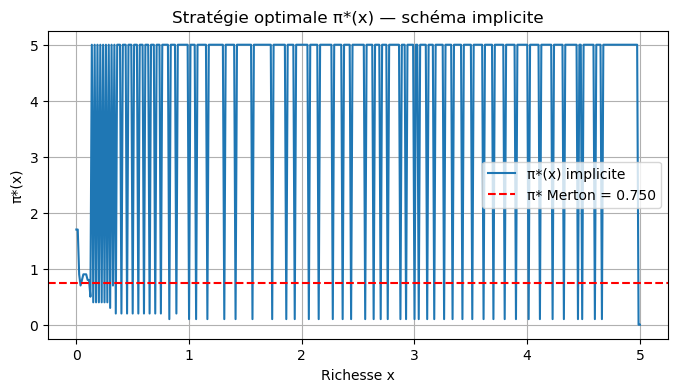

=== ORDRE DE CONVERGENCE IMPLICITE (L∞ intérieur) ===
Ordre ≈ 0.552


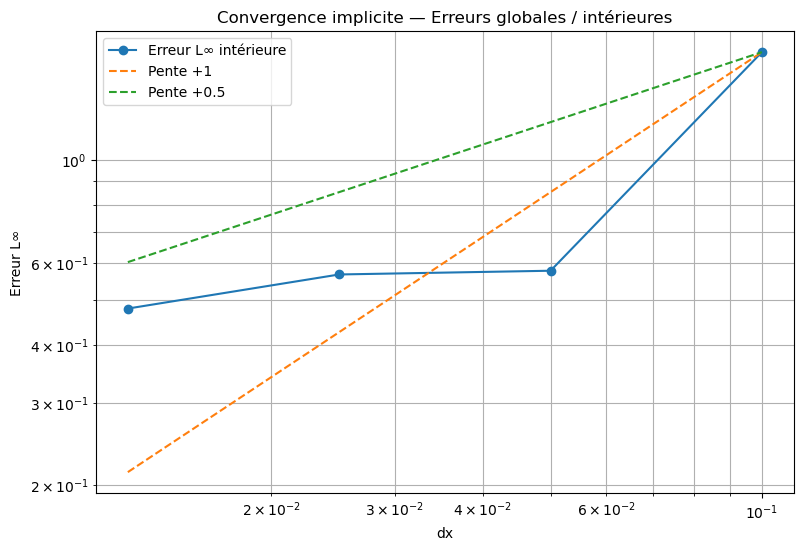


=== ERREURS IMPLICITE ===
dx=1.2497e-02 | L∞ global=4.9217e+02 | L∞ intérieur=4.7973e-01
dx=2.4995e-02 | L∞ global=4.4845e+02 | L∞ intérieur=5.6791e-01
dx=4.9990e-02 | L∞ global=4.2353e+02 | L∞ intérieur=5.7852e-01
dx=9.9980e-02 | L∞ global=4.0894e+02 | L∞ intérieur=1.7076e+00


In [7]:
# ==============================================================
# 1) Résolution implicite + comparaison avec V_exact
# ==============================================================

V_imp, pi_imp, xgrid, tgrid = solve_HJB_implicite(
    r, mu, sigma, gamma, T, U,
    x_min=x_min, x_max=x_max, Nx=Nx, Nt=Nt,
    max_hw=5
)

# Solution analytique
V_theo = V_exact(0, xgrid, r, mu, sigma, gamma, T)

plt.figure(figsize=(8, 4))
plt.plot(xgrid, V_imp[0, :], label="V implicite (t=0)")
plt.plot(xgrid, V_theo, '--', label="V analytique (Merton)")
plt.xlabel("Richesse x")
plt.ylabel("V(0,x)")
plt.title("Comparaison V_implicite vs V_exacte (Merton)")
plt.grid(True)
plt.legend()
plt.show()


# ==============================================================
# 2) Stratégie optimale π*(x)
# ==============================================================

pi0_imp = pi_imp[0, :]

plt.figure(figsize=(8, 4))
plt.plot(xgrid, pi0_imp, label="π*(x) implicite")
plt.axhline(pi_merton, color='r', linestyle='--',
            label=f"π* Merton = {pi_merton:.3f}")
plt.xlabel("Richesse x")
plt.ylabel("π*(x)")
plt.title("Stratégie optimale π*(x) — schéma implicite")
plt.grid(True)
plt.legend()
plt.show()


# ==============================================================
# 3) TEST DE CONVERGENCE :  L∞ intérieur
# ==============================================================

resolutions = [50, 100, 200, 400]
errors_Linf_global = []
errors_Linf_inner  = []
dx_values = []

eps = 0.05   # enlève 5% aux bords

for Nx_test in resolutions:

    dx_test = (x_max - x_min) / Nx_test
    dx_values.append(dx_test)

    Nt_test = Nx_test   # IMPORTANT : dt ≈ dx pour bonne convergence

    V_tmp, pi_tmp, x_tmp, t_tmp = solve_HJB_implicite(
        r, mu, sigma, gamma, T, U,
        x_min=x_min, x_max=x_max, Nx=Nx_test, Nt=Nt_test,
        max_hw=3
    )

    V_th = V_exact(0, x_tmp, r, mu, sigma, gamma, T)

    # erreur globale
    err_g = np.max(np.abs(V_tmp[0, :] - V_th))
    errors_Linf_global.append(err_g)

    # erreur intérieure
    mask = (x_tmp > x_min + eps*(x_max - x_min)) & \
           (x_tmp < x_max - eps*(x_max - x_min))
    err_i = np.max(np.abs(V_tmp[0, mask] - V_th[mask]))
    errors_Linf_inner.append(err_i)


# ==============================================================
# 4) Ordre de convergence (L∞ intérieur)
# ==============================================================

dx_values = np.array(dx_values)
errors_Linf_inner = np.array(errors_Linf_inner)

# trier pour graphes + pente
idx = np.argsort(dx_values)
dx_values = dx_values[idx]
errors_Linf_inner = errors_Linf_inner[idx]
errors_Linf_global = np.array(errors_Linf_global)[idx]

order_inner = np.polyfit(np.log(dx_values), np.log(errors_Linf_inner), 1)[0]

print("=== ORDRE DE CONVERGENCE IMPLICITE (L∞ intérieur) ===")
print(f"Ordre ≈ {order_inner:.3f}")


# ==============================================================
# 5) Graphiques loglog
# ==============================================================

plt.figure(figsize=(9,6))
plt.loglog(dx_values, errors_Linf_inner,  'o-', label="Erreur L∞ intérieure")

ref = errors_Linf_inner[-1]
plt.loglog(dx_values, ref*(dx_values/dx_values[-1])**1,
           '--', label="Pente +1")
plt.loglog(dx_values, ref*(dx_values/dx_values[-1])**0.5,
           '--', label="Pente +0.5")

plt.xlabel("dx")
plt.ylabel("Erreur L∞")
plt.title("Convergence implicite — Erreurs globales / intérieures")
plt.grid(True, which="both")
plt.legend()
plt.show()


# ==============================================================
# 6) Tableau des erreurs
# ==============================================================

print("\n=== ERREURS IMPLICITE ===")
for dx, e1, e2 in zip(dx_values, errors_Linf_global, errors_Linf_inner):
    print(f"dx={dx:.4e} | L∞ global={e1:.4e} | L∞ intérieur={e2:.4e}")


## 5.Schéma Semi-Implicite

### 5.1.Fonction : Solveur HJB Semi-Implicite(CN)

In [8]:
import numpy as np

# ============================================================
#  Derivée U'(x) numérique (monotone)
# ============================================================
def U_prime_num(U, x, dx):
    return (U(x+dx) - U(x)) / dx     # forward (car x_min ≈ 0)



# ============================================================
#  Matrice de diffusion uniquement (CN)
# ============================================================
def build_system_diffusion_CN(b, dx, dt_half):
    N = len(b)-1

    lower = np.zeros(N+1)
    diag  = np.ones(N+1)
    upper = np.zeros(N+1)

    for i in range(1, N):
        diff = dt_half * b[i] / dx**2
        lower[i] = -diff
        upper[i] = -diff
        diag[i]  = 1 + 2*diff

    # BC Neumann
    diag[0]  = 1; upper[0] = -1
    diag[-1] = 1; lower[-1] = -1

    return lower, diag, upper


# ============================================================
#  SCHEMA SEMI-IMPLICITE (Crank–Nicolson)
# ============================================================
def solve_HJB_semi_implicite(
        r, mu, sigma, gamma, T, U,
        x_min=1e-3, x_max=5.0, Nx=400, Nt=200,
        pi_min=-1.5, pi_max=1.5):

    dx = (x_max - x_min)/Nx
    dt = T/Nt
    x  = np.linspace(x_min, x_max, Nx+1)
    t_grid = np.linspace(0, T, Nt+1)

    eps = 1e-8

    V = np.zeros((Nt+1, Nx+1))
    V[-1,:] = U(x)


    # ================
    # Boucle backward
    # ================
    for n in range(Nt-1, -1, -1):

        Vn1 = V[n+1,:]

        # ---------------------
        # dérivées Vx, Vxx à n+1
        # ---------------------
        Vx  = np.zeros_like(Vn1)
        Vxx = np.zeros_like(Vn1)

        # upwind pour la convection explicite
        for i in range(1, Nx):
            if (mu-r) >= 0:
                Vx[i] = (Vn1[i] - Vn1[i-1]) / dx
            else:
                Vx[i] = (Vn1[i+1] - Vn1[i]) / dx

            Vxx[i] = (Vn1[i+1] - 2*Vn1[i] + Vn1[i-1]) / dx**2

        Vx[0], Vx[-1] = Vx[1], Vx[-2]
        Vxx[0], Vxx[-1] = Vxx[1], Vxx[-2]

        # ----------------------------
        # stratégie explicite π*
        # ----------------------------
        denom = sigma**2 * x * Vxx
        denom = np.where(np.abs(denom)<eps, eps*np.sign(denom), denom)

        pi = - (mu - r) * Vx / denom
        pi = np.clip(pi, pi_min, pi_max)

        # convection explicite
        a = x * (r + pi*(mu-r))
        conv = a * Vx

        # diffusion
        b = 0.5 * x**2 * pi**2 * sigma**2
        b = np.maximum(b, eps)    # éviter dégénérescence x→0

        RHS = Vn1 - dt*conv - 0.5*dt*(b*Vxx)

        # BC Neumann
        RHS[0]  = Vn1[1]  - dx * U_prime_num(U, x[0], dx)
        RHS[-1] = Vn1[-2] + dx * U_prime_num(U, x[-1], dx)

        # Matrice CN (seule la diffusion est implicite)
        lower, diag, upper = build_system_diffusion_CN(b, dx, dt/2)

        V[n,:] = solve_tridiag(lower, diag, upper, RHS)

    # stratégie finale à t=0
    V0 = V[0,:]

    Vx0 = np.zeros_like(V0)
    Vx0[1:-1] = (V0[2:] - V0[:-2]) / (2*dx)
    Vx0[0], Vx0[-1] = Vx0[1], Vx0[-2]

    Vxx0 = np.zeros_like(V0)
    Vxx0[1:-1] = (V0[2:] - 2*V0[1:-1] + V0[:-2]) / dx**2
    Vxx0[0], Vxx0[-1] = Vxx0[1], Vxx0[-2]

    denom0 = sigma**2 * x * Vxx0
    denom0 = np.where(np.abs(denom0)<eps, eps*np.sign(denom0), denom0)

    pi0 = - (mu-r) * Vx0 / denom0
    pi0 = np.clip(pi0, pi_min, pi_max)

    return V, pi0, x, t_grid


### 5.2.Exécution : Schéma Semi-Implicite

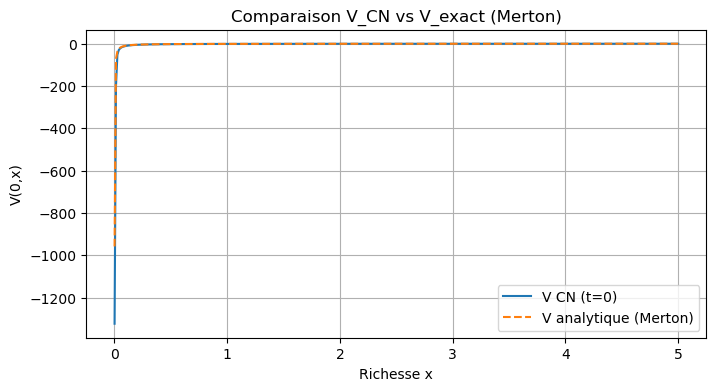

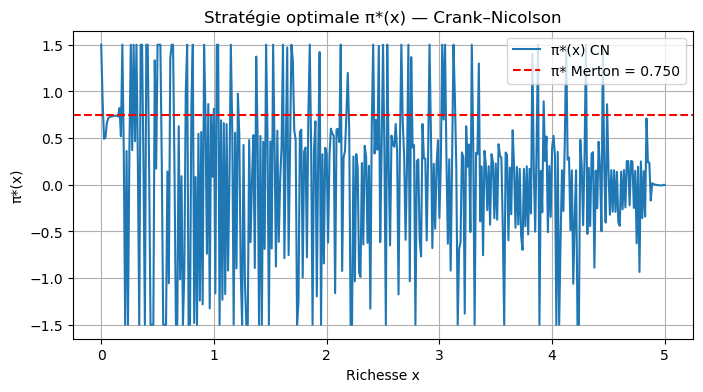

=== ORDRE DE CONVERGENCE Crank–Nicolson (L∞ intérieur) ===
Ordre L∞ intérieur : 0.333


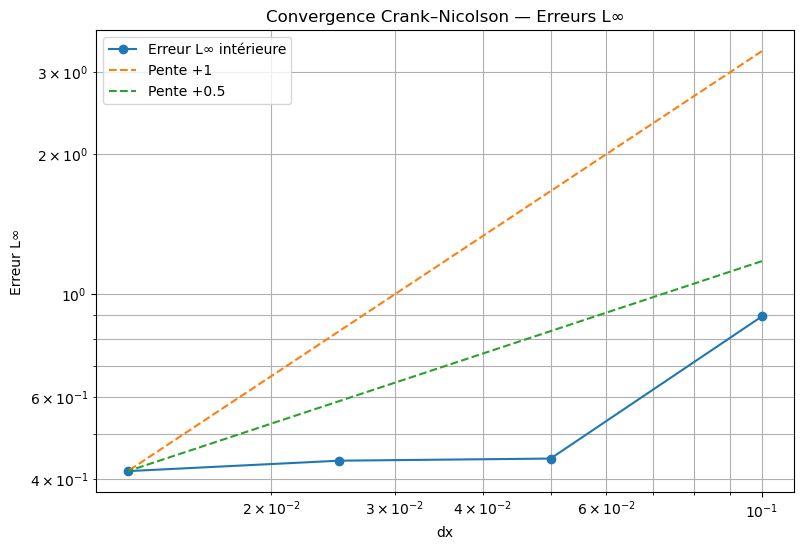


=== ERREURS Crank–Nicolson ===
dx=9.9980e-02 | L∞ global=2.8567e+02 | L∞ intérieur=8.9373e-01
dx=4.9990e-02 | L∞ global=2.9774e+02 | L∞ intérieur=4.4207e-01
dx=2.4995e-02 | L∞ global=3.2119e+02 | L∞ intérieur=4.3745e-01
dx=1.2497e-02 | L∞ global=3.6534e+02 | L∞ intérieur=4.1543e-01


In [9]:
# ==============================================================
# 0) Paramètres + solution exacte
# ==============================================================

# Grille principale
Nx = 400
Nt = 200
x_min = 1e-3
x_max = 5.0

dx = (x_max - x_min)/Nx
dt = T/Nt

xgrid = np.linspace(x_min, x_max, Nx+1)
tgrid = np.linspace(0, T, Nt+1)

# Solution analytique
V_theo = V_exact(0, xgrid, r, mu, sigma, gamma, T)


# ==============================================================
# 1) Résolution Crank–Nicolson + comparaison avec V_exact
# ==============================================================

V_cn, pi_cn0, xgrid, tgrid = solve_HJB_semi_implicite(
    r, mu, sigma, gamma, T, U,
    x_min=x_min, x_max=x_max,
    Nx=Nx, Nt=Nt,
    pi_min=-1.5, pi_max=1.5
)

plt.figure(figsize=(8, 4))
plt.plot(xgrid, V_cn[0, :], label="V CN (t=0)")
plt.plot(xgrid, V_theo, '--', label="V analytique (Merton)")
plt.xlabel("Richesse x")
plt.ylabel("V(0,x)")
plt.title("Comparaison V_CN vs V_exact (Merton)")
plt.grid(True)
plt.legend()
plt.show()


# ==============================================================
# 2) Stratégie optimale π*(x) — Crank–Nicolson
# ==============================================================

pi_merton = (mu - r) / (gamma * sigma**2)

plt.figure(figsize=(8, 4))
plt.plot(xgrid, pi_cn0, label="π*(x) CN")
plt.axhline(pi_merton, color='r', linestyle='--', label=f"π* Merton = {pi_merton:.3f}")
plt.xlabel("Richesse x")
plt.ylabel("π*(x)")
plt.title("Stratégie optimale π*(x) — Crank–Nicolson")
plt.grid(True)
plt.legend()
plt.show()


# ==============================================================
# 3) Test de convergence Crank–Nicolson
# ==============================================================

resolutions = [50, 100, 200, 400]
errors_Linf_global = []
errors_Linf_inner  = []
dx_values = []

eps = 0.05   # enlever 5% du domaine aux bords

for Nx_test in resolutions:

    dx_test = (x_max - x_min) / Nx_test
    dx_values.append(dx_test)

    x_test = np.linspace(x_min, x_max, Nx_test + 1)
    t_test = np.linspace(0, T, Nt + 1)
    dt_test = T / Nt

    # Résolution CN
    V_tmp, pi_tmp, x_tmp, t_tmp = solve_HJB_semi_implicite(
        r, mu, sigma, gamma, T, U,
        x_min=x_min, x_max=x_max,
        Nx=Nx_test, Nt=Nt,
        pi_min=-1.5, pi_max=1.5
    )

    # solution exacte
    V_th = V_exact(0, x_test, r, mu, sigma, gamma, T)

    # erreur L∞ globale
    err_global = np.max(np.abs(V_tmp[0, :] - V_th))
    errors_Linf_global.append(err_global)

    # erreur intérieure (on enlève 5% à gauche et à droite)
    mask = (x_test > x_min + eps*(x_max-x_min)) & (x_test < x_max - eps*(x_max-x_min))
    err_inner = np.max(np.abs(V_tmp[0, mask] - V_th[mask]))
    errors_Linf_inner.append(err_inner)


# ==============================================================
# 4) Ordre de convergence L∞ intérieur
# ==============================================================

dx_values = np.array(dx_values)
log_dx     = np.log(dx_values)
log_err_in = np.log(errors_Linf_inner)

order_inner = np.polyfit(log_dx, log_err_in, 1)[0]

print("=== ORDRE DE CONVERGENCE Crank–Nicolson (L∞ intérieur) ===")
print(f"Ordre L∞ intérieur : {order_inner:.3f}")


# ==============================================================
# 5) Graphique log-log + pentes de référence
# ==============================================================

plt.figure(figsize=(9, 6))
plt.loglog(dx_values, errors_Linf_inner,  'o-', label="Erreur L∞ intérieure")

# pentes références
ref = errors_Linf_inner[-1]
plt.loglog(dx_values, ref*(dx_values/dx_values[-1])**1, '--', label="Pente +1")
plt.loglog(dx_values, ref*(dx_values/dx_values[-1])**0.5, '--', label="Pente +0.5")

plt.xlabel("dx")
plt.ylabel("Erreur L∞")
plt.title("Convergence Crank–Nicolson — Erreurs L∞")
plt.grid(True, which="both")
plt.legend()
plt.show()


# ==============================================================
# 6) Tableau des erreurs
# ==============================================================

print("\n=== ERREURS Crank–Nicolson ===")
for dx, e1, e2 in zip(dx_values, errors_Linf_global, errors_Linf_inner):
    print(f"dx={dx:.4e} | L∞ global={e1:.4e} | L∞ intérieur={e2:.4e}")


## 7.Analyse paramétrique 

### 7.1 Fonctions auxiliaires et définition de l’analyseur 

In [10]:
def generer_error(V_num, V_exact, x, x_min, x_max, eps_ratio=0.05):
    """
    Calcule l'erreur L∞ intérieure (hors bords).
    
    eps_ratio = proportion exclue à gauche et à droite
                0.05 = on enlève 5% du domaine
    """

    L = x_max - x_min
    eps = eps_ratio * L

    mask = (x > x_min + eps) & (x < x_max - eps)

    if not np.any(mask):
        return np.max(np.abs(V_num - V_exact))   # fallback

    return np.max(np.abs(V_num[mask] - V_exact[mask]))

def analyse_param(
    r, mu, sigma, gamma, T,
    x_min, x_max, Nx, Nt, U
):

   
    def solve_and_err(r_loc, mu_loc, sigma_loc, gamma_loc,
                      Nx_loc, Nt_loc, label):

        # Résolution semi-implicite
        V, pi0, x, t = solve_HJB_semi_implicite(
            r_loc, mu_loc, sigma_loc, gamma_loc, T, U,
            x_min=x_min, x_max=x_max,
            Nx=Nx_loc, Nt=Nt_loc
        )

        # V(0,x)
        V0 = V[0, :]

        # Réf analytique
        V_th = V_exact(0, x, r_loc, mu_loc, sigma_loc, gamma_loc, T)
        pi_M = pi_M = (mu_loc - r_loc) / (gamma_loc * sigma_loc**2)


        # Erreurs intérieures
        err_V  = generer_error(V0, V_th, x, x_min, x_max)
        err_pi = generer_error(pi0, pi_M*np.ones_like(x),
                                     x, x_min, x_max)

        return x, pi0, pi_M, err_V, err_pi, label


    # ====================================================
    #                PARTIE 1 : PARAMÈTRES FINANCIERS
    # ====================================================
    params = {
        "taux r": [
            ("r=0.01", 0.01, mu, sigma, gamma),
            ("r=0.03", 0.03, mu, sigma, gamma),
            ("r=0.05", 0.05, mu, sigma, gamma)
        ],

        "drift μ": [
            ("mu=0.10", r, 0.10, sigma, gamma),
            ("mu=0.15", r, 0.15, sigma, gamma),
            ("mu=0.25", r, 0.25, sigma, gamma)
        ],

        "volatilité σ": [
            ("sigma=0.1", r, mu, 0.1, gamma),
            ("sigma=0.2", r, mu, 0.2, gamma),
            ("sigma=0.3", r, mu, 0.3, gamma)
        ],

        "aversion γ": [
            ("gamma=1", r, mu, sigma, 1),
            ("gamma=3", r, mu, sigma, 3),
            ("gamma=5", r, mu, sigma, 5)
        ]
    }

    print("\n==================== PARAMÈTRES FINANCIERS ====================\n")

    for param_name, cases in params.items():

        print(f"\n********** {param_name.upper()} **********")
        print("label           err_V(int)        err_pi(int)")
        print("---------------------------------------------------")

        plt.figure(figsize=(10,4))

        for label, r_loc, mu_loc, sigma_loc, gamma_loc in cases:
            x, pi0, piM, errV, errPi, _ = solve_and_err(
                r_loc, mu_loc, sigma_loc, gamma_loc, Nx, Nt, label
            )

            print(f"{label:<12}  {errV:.3e}     {errPi:.3e}")
            plt.plot(x, pi0, label=label)

        plt.title(f"Influence de {param_name} sur π*(x)")
        plt.xlabel("x"); plt.ylabel("π*(x)")
        plt.grid(True); plt.legend()
        plt.show()


    # ====================================================
    #                PARTIE 2 : MAILLAGE EN X
    # ====================================================
    print("\n==================== MAILLAGE EN X ====================\n")
    plt.figure(figsize=(10,4))

    for Nx_loc in [50, 100, 200, 400]:
        x, pi0, piM, errV, errPi, _ = solve_and_err(
            r, mu, sigma, gamma, Nx_loc, Nt, f"Nx={Nx_loc}"
        )
        print(f"Nx={Nx_loc:<6}  errV={errV:.3e}   errPi={errPi:.3e}")
        plt.plot(x, pi0, label=f"Nx={Nx_loc}")

    plt.title("Influence de Nx sur π*(x)")
    plt.xlabel("x"); plt.ylabel("π*(x)")
    plt.grid(True); plt.legend()
    plt.show()


    # ====================================================
    #                PARTIE 3 : MAILLAGE EN T
    # ====================================================
    print("\n==================== MAILLAGE EN T ====================\n")
    plt.figure(figsize=(10,4))

    for Nt_loc in [50, 100, 200, 400]:
        x, pi0, piM, errV, errPi, _ = solve_and_err(
            r, mu, sigma, gamma, Nx, Nt_loc, f"Nt={Nt_loc}"
        )
        print(f"Nt={Nt_loc:<6}  errV={errV:.3e}   errPi={errPi:.3e}")
        plt.plot(x, pi0, label=f"Nt={Nt_loc}")

    plt.title("Influence de Nt sur π*(x)")
    plt.xlabel("x"); plt.ylabel("π*(x)")
    plt.grid(True); plt.legend()
    plt.show()

    return


### 7.2 Exécution


==================== PARAMÈTRES FINANCIERS ====================


********** TAUX R **********
label           err_V(int)        err_pi(int)
---------------------------------------------------
r=0.01        4.122e-01     2.375e+00
r=0.03        4.283e-01     2.125e+00
r=0.05        4.601e-01     1.875e+00


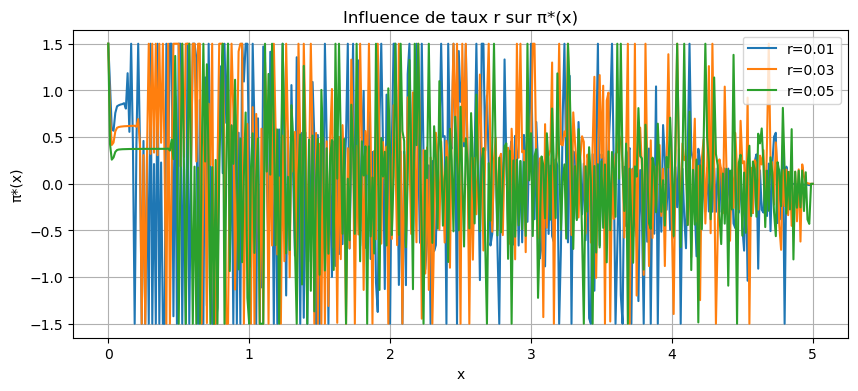


********** DRIFT Μ **********
label           err_V(int)        err_pi(int)
---------------------------------------------------
mu=0.10       5.914e-01     2.500e+00
mu=0.15       1.416e+00     3.125e+00
mu=0.25       2.919e+00     4.375e+00


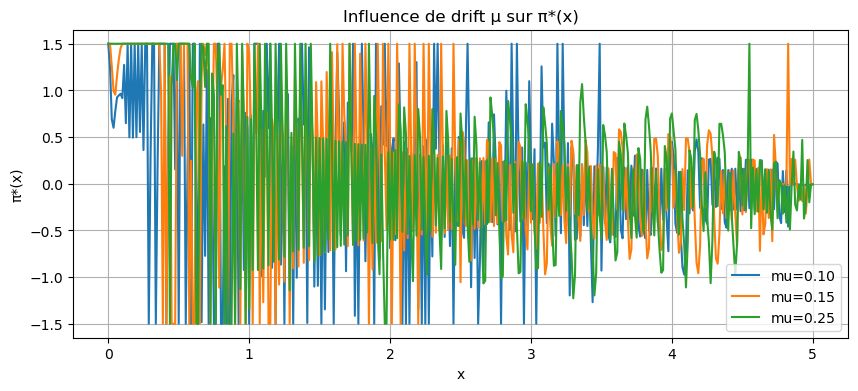


********** VOLATILITÉ Σ **********
label           err_V(int)        err_pi(int)
---------------------------------------------------
sigma=0.1     8.615e-01     4.500e+00
sigma=0.2     4.154e-01     2.250e+00
sigma=0.3     2.790e-01     1.833e+00


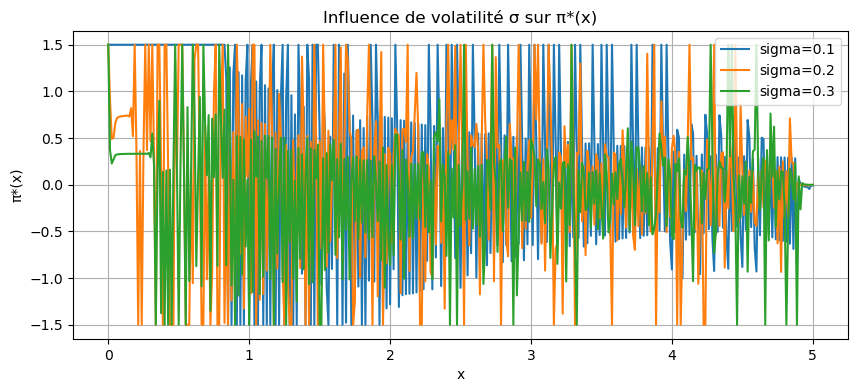


********** AVERSION Γ **********
label           err_V(int)        err_pi(int)
---------------------------------------------------
gamma=1       2.575e-01     3.000e+00
gamma=3       5.141e-01     2.000e+00
gamma=5       6.732e-01     1.800e+00


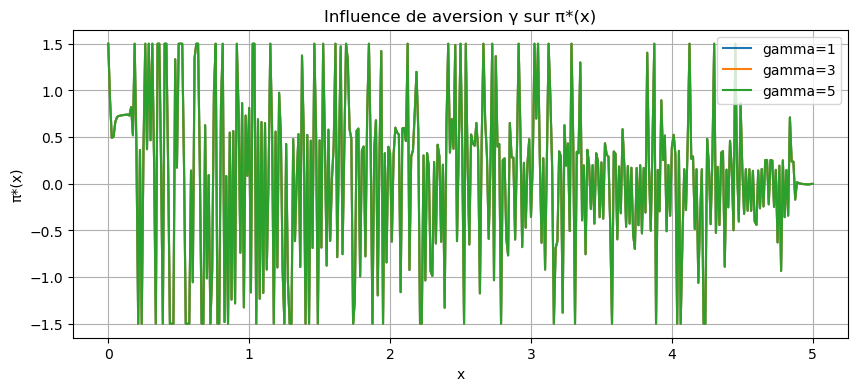


==================== MAILLAGE EN X ====================

Nx=50      errV=8.937e-01   errPi=2.250e+00
Nx=100     errV=4.421e-01   errPi=2.250e+00
Nx=200     errV=4.375e-01   errPi=2.250e+00
Nx=400     errV=4.154e-01   errPi=2.250e+00


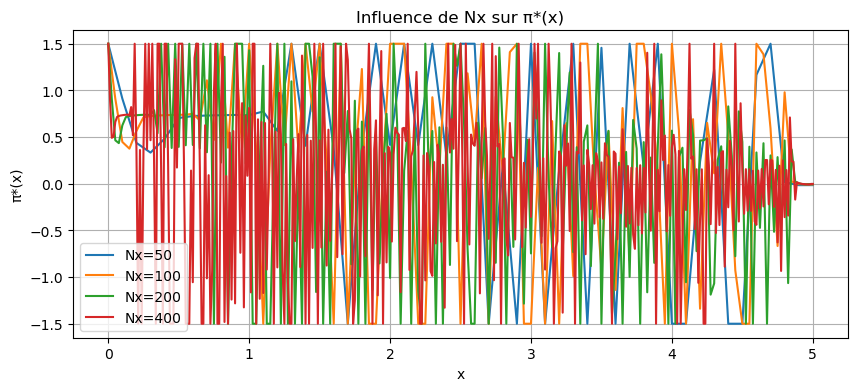


==================== MAILLAGE EN T ====================

Nt=50      errV=4.351e-01   errPi=2.250e+00
Nt=100     errV=4.288e-01   errPi=2.250e+00
Nt=200     errV=4.154e-01   errPi=2.250e+00
Nt=400     errV=3.978e-01   errPi=2.250e+00


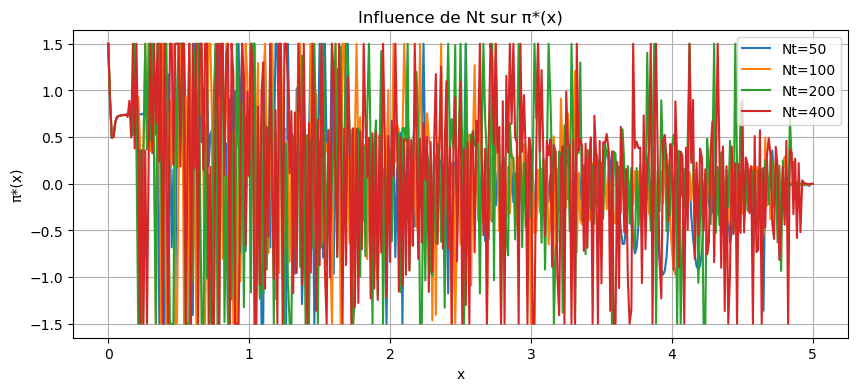

In [11]:
analyse_param(
    r, mu, sigma, gamma, T,
    x_min, x_max, Nx, Nt, U
)


 ### 8.ANALYSE NUMÉRIQUE DE LA HJB — UTILITÉ

### 8.1.Fonctions auxiliaires et définition de l’analyseur 

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
#  L∞ intérieur entre deux solutions numériques (réf = fine)
# ---------------------------------------------------------
def compute_inner_error_num(V_coarse, x_coarse, V_ref, x_ref,
                            x_min, x_max, eps=0.05):
    # interpole la réf sur la grille coarse
    V_ref_interp = np.interp(x_coarse, x_ref, V_ref)

    # masque intérieur
    mask = (x_coarse > x_min + eps*(x_max-x_min)) & \
           (x_coarse < x_max - eps*(x_max-x_min))

    return np.max(np.abs(V_coarse[mask] - V_ref_interp[mask]))


# =====================================================================
#  ANALYSE UTILITÉ GÉNÉRALE : V + π pour plusieurs Nx (réf = Nx max)
# =====================================================================
def analyse_utilite_generale(U, nom_utilite,
                             r, mu, sigma, gamma, T,
                             x_min=1e-3, x_max=5.0,
                             Nx_list=(50, 100, 200, 400),
                             Nt=200):

    Nx_list = list(Nx_list)
    Nx_ref = max(Nx_list)

    # --- solution de référence ---
    V_ref, pi_ref0, x_ref, t_ref = solve_HJB_semi_implicite(
        r, mu, sigma, gamma, T, U,
        x_min=x_min, x_max=x_max,
        Nx=Nx_ref, Nt=Nt
    )
    V0_ref = V_ref[0, :]

    # stockage
    all_x   = {}
    all_V0  = {}
    all_pi0 = {}
    err_V_int = {}

    print("\n====================  ANALYSE UTILITÉ  ====================")
    print(f"Utilité : {nom_utilite}")
    print("\nNx      err_V(int)")
    print("-----------------------------------------")

    for Nx in Nx_list:
        V_num, pi0_num, x_num, _ = solve_HJB_semi_implicite(
            r, mu, sigma, gamma, T, U,
            x_min=x_min, x_max=x_max,
            Nx=Nx, Nt=Nt
        )
        V0_num = V_num[0, :]

        # erreur par rapport à la référence Nx_ref
        errV = compute_inner_error_num(
            V0_num, x_num, V0_ref, x_ref, x_min, x_max
        )

        all_x[Nx]   = x_num
        all_V0[Nx]  = V0_num
        all_pi0[Nx] = pi0_num
        err_V_int[Nx] = errV

        print(f"{Nx:<7d} {errV:10.3e}")

    # ===================== GRAPHE π*(x) ======================
    plt.figure(figsize=(9,4))
    for Nx in Nx_list:
        plt.plot(all_x[Nx], all_pi0[Nx], label=f"Nx={Nx}")
    plt.title(f"Stratégies π*(x) — utilité {nom_utilite}")
    plt.xlabel("x")
    plt.ylabel("π*(x)")
    plt.grid(True)
    plt.legend()
    plt.show()

    # ===================== GRAPHE V(0,x) =====================
    plt.figure(figsize=(9,4))
    for Nx in Nx_list:
        plt.plot(all_x[Nx], all_V0[Nx], label=f"Nx={Nx}")
    plt.title(f"Valeur V(0,x) — utilité {nom_utilite}")
    plt.xlabel("x")
    plt.ylabel("V(0,x)")
    plt.grid(True)
    plt.legend()
    plt.show()

    # ========== ERREURS vs Nx (log-log pour V) ===============
    Nx_arr   = np.array(Nx_list, dtype=float)
    err_arr  = np.array([err_V_int[N] for N in Nx_list])

    plt.figure(figsize=(6,4))
    plt.loglog(Nx_arr, err_arr, "o-")
    plt.xlabel("Nx")
    plt.ylabel("Erreur L∞ intérieure sur V")
    plt.title(f"Erreur vs Nx — utilité {nom_utilite}")
    plt.grid(True, which="both")
    plt.show()

    return all_x, all_V0, all_pi0, err_V_int


### 8.2.Exécution


====================  ANALYSE UTILITÉ  ====================
Utilité : x^2/2

Nx      err_V(int)
-----------------------------------------
50       3.045e-01
100      2.471e-01
200      8.409e-02
400      0.000e+00


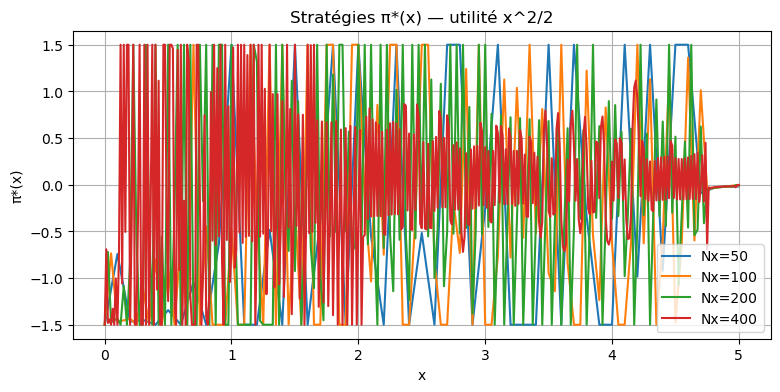

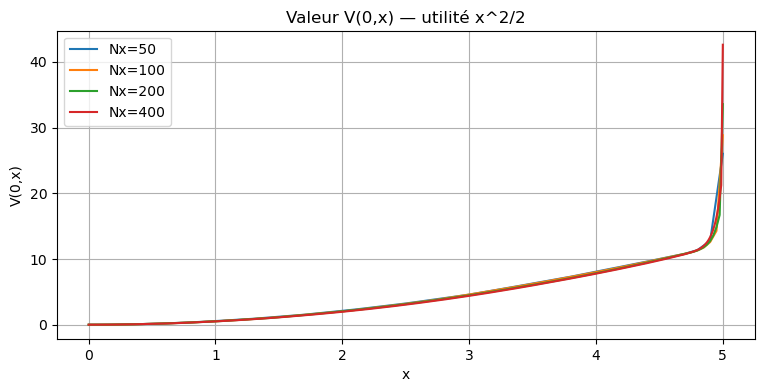

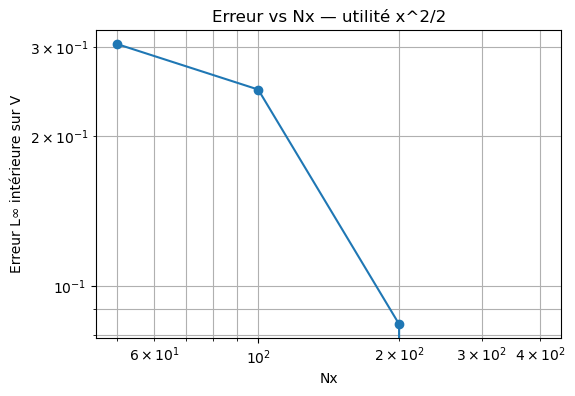

In [13]:
def U_quad(x):
    return 0.5 * x**2
all_x, all_V0, all_pi0, err_V = analyse_utilite_generale(
    U_quad, "x^2/2",
    r, mu, sigma, gamma, T,
    x_min=x_min, x_max=x_max,
    Nx_list=(50, 100, 200, 400),
    Nt=Nt
)



====================  ANALYSE UTILITÉ  ====================
Utilité : Logarithmique

Nx      err_V(int)
-----------------------------------------
50       7.019e-02
100      4.751e-02
200      2.271e-02
400      0.000e+00


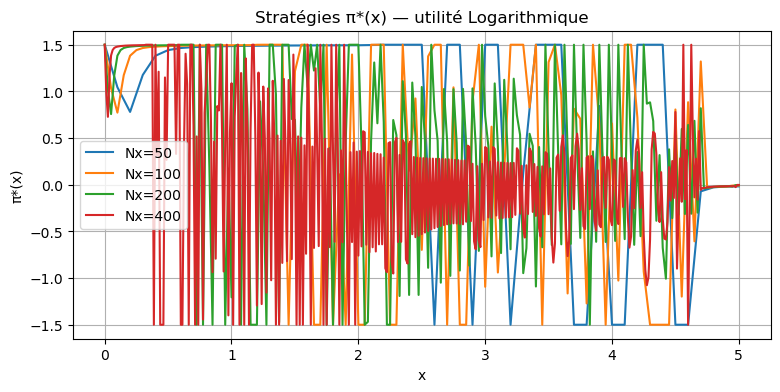

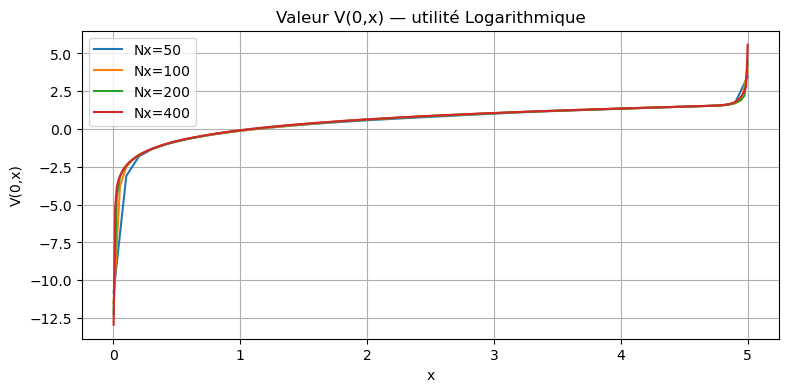

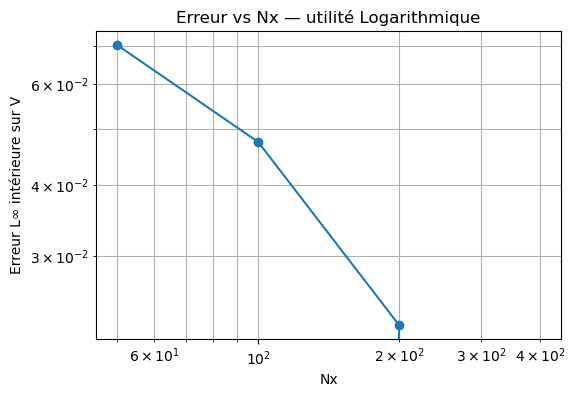

In [14]:
def U_log(x):
    import numpy as np
    return np.log(np.maximum(x, 1e-12))

U = U_log

all_x, all_V0, all_pi0, err_V = analyse_utilite_generale(
    U, "Logarithmique",
    r, mu, sigma, gamma, T,
    x_min=x_min, x_max=x_max,
    Nx_list=(50, 100, 200, 400),
    Nt=Nt
)



====================  ANALYSE UTILITÉ  ====================
Utilité : sqrt(x)

Nx      err_V(int)
-----------------------------------------
50       5.500e-02
100      3.070e-02
200      1.338e-02
400      0.000e+00


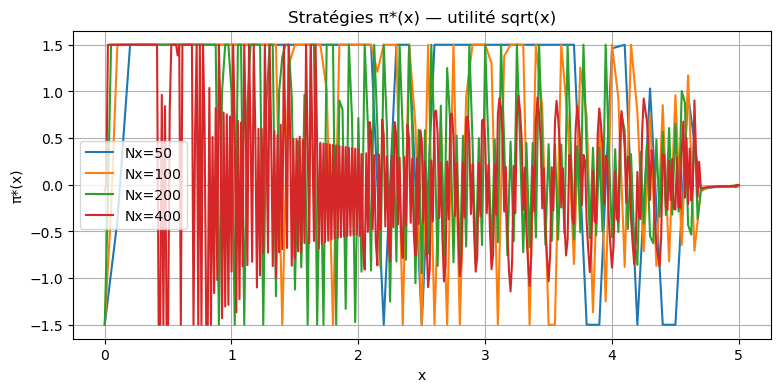

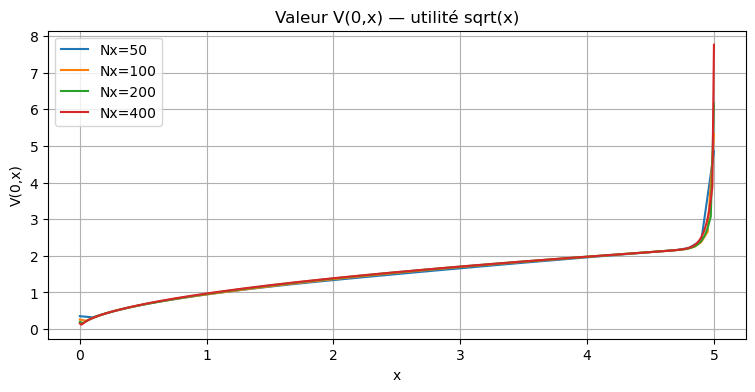

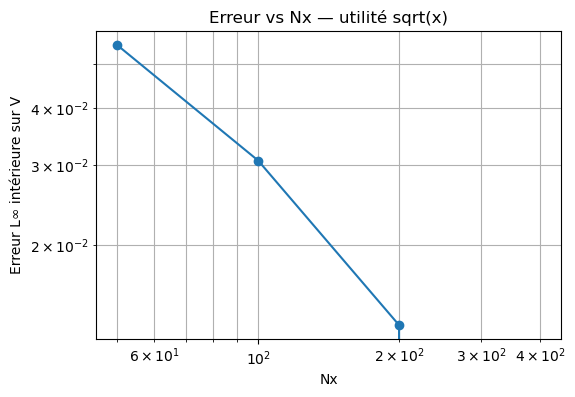

In [15]:
def U_sqrt(x):
    import numpy as np
    return np.sqrt(np.maximum(x, 0))

U = U_sqrt

all_x, all_V0, all_pi0, err_V = analyse_utilite_generale(
    U, "sqrt(x)",
    r, mu, sigma, gamma, T,
    x_min=x_min, x_max=x_max,
    Nx_list=(50, 100, 200, 400),
    Nt=Nt
)
